/var/folders/h5/1rb1tj8x0vs85cxtszq9_hdm0000gn/T/ipykernel_77651/3721992959.py:12: ParserWarning: Skipping line 184566: expected 9 fields, saw 12

  df = pd.read_csv(
/var/folders/h5/1rb1tj8x0vs85cxtszq9_hdm0000gn/T/ipykernel_77651/3721992959.py:12: DtypeWarning: Columns (0: new_long) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(


Rows successfully loaded: 199852
Columns detected: ['emisno', 'centername', 'institution_name', 'centreno', 'quintile', 'ward_id', 'street_address', 'new_long', 'new_lat;;;;']
                                              emisno centername  \
0  200100005,ABERDEEN SECONDARY SCHOOL (20),ABERD...        NaN   
1  200100012,ADELAIDE GYMNASIUM,ADELAIDE GYMNASIU...        NaN   
2  200100018,AEROVILLE(SOMERSET EAST) (20),AEROVI...        NaN   
3  200100019,Al Azhar Institute,AL-AZHAR PRIMARY ...        NaN   
4  200100021,ALEXANDER ROAD HIGH SCHOOL,ALEXANDER...        NaN   

  institution_name centreno quintile ward_id street_address new_long  \
0              NaN      NaN      NaN     NaN            NaN      NaN   
1              NaN      NaN      NaN     NaN            NaN      NaN   
2              NaN      NaN      NaN     NaN            NaN      NaN   
3              NaN      NaN      NaN     NaN            NaN      NaN   
4              NaN      NaN      NaN     NaN            NaN  

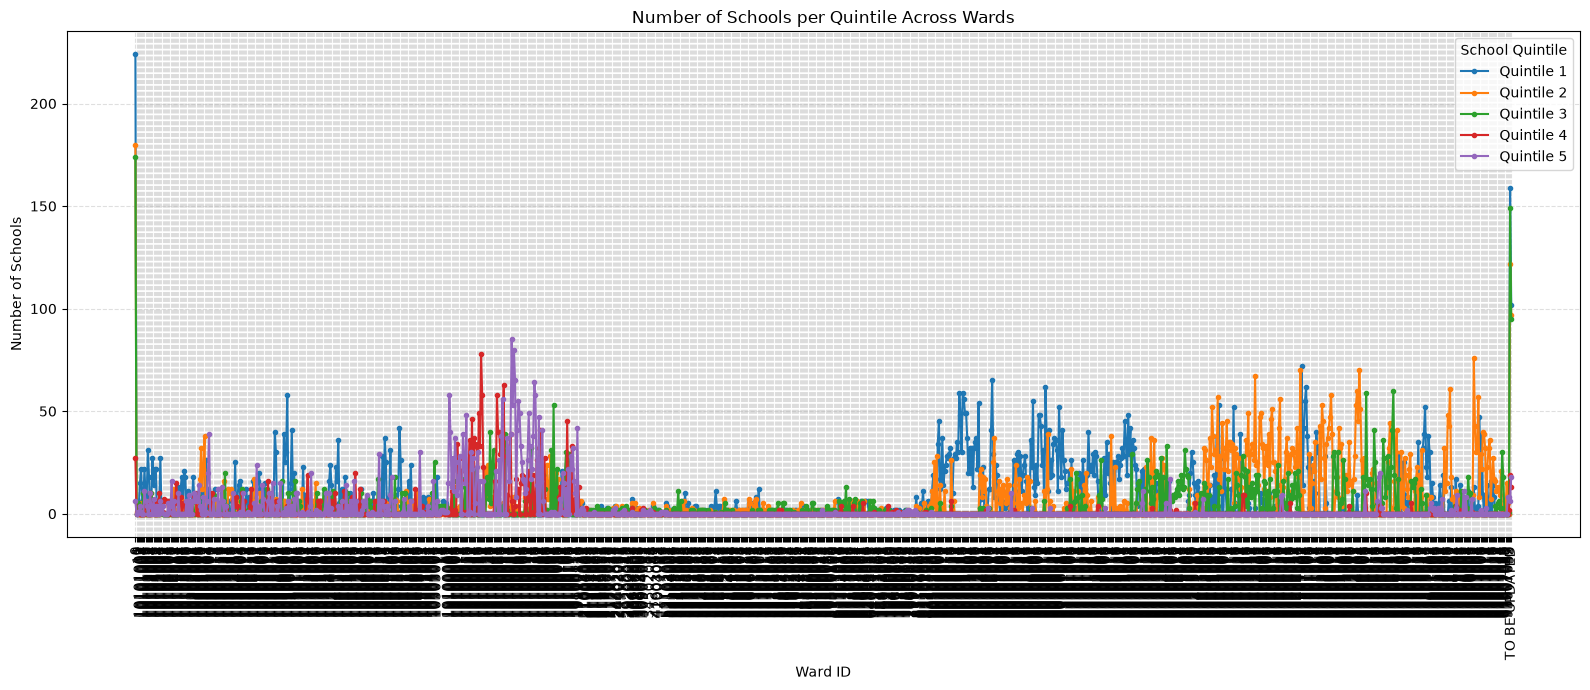

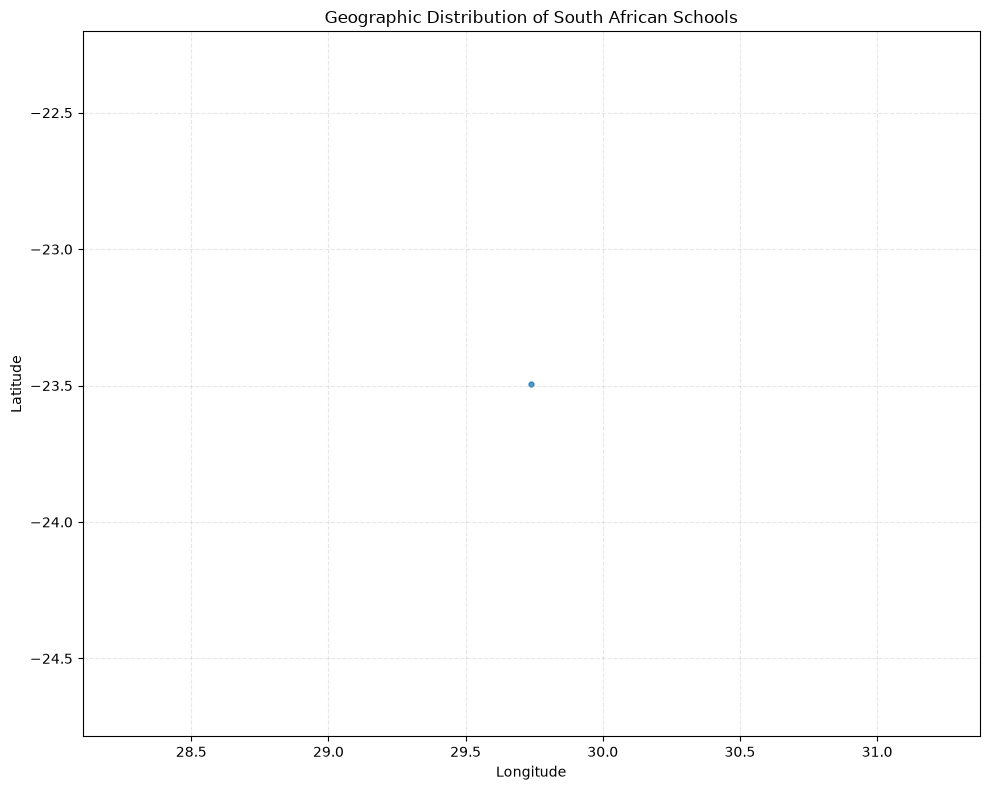

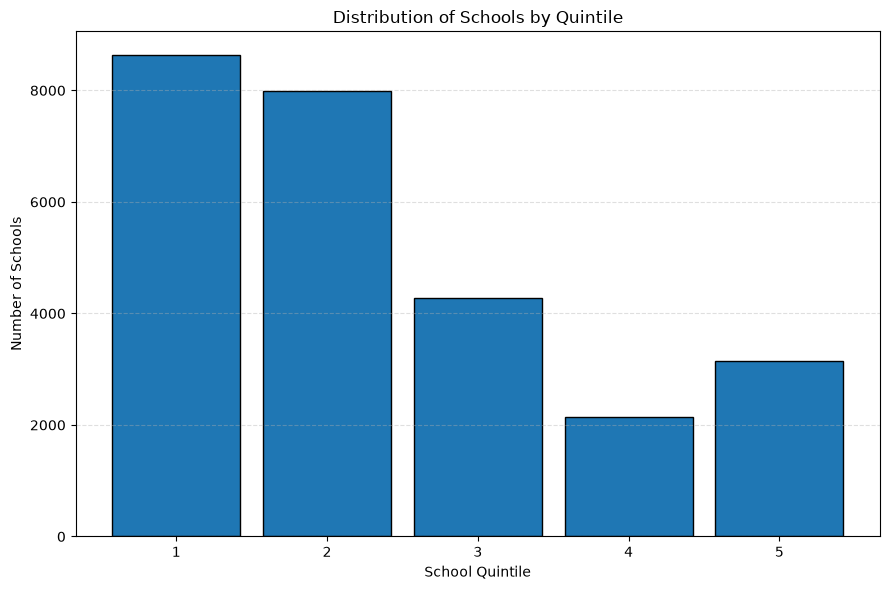


Number of schools in each quintile:
Quintile
1    8628
2    7991
3    4279
4    2145
5    3146
Name: count, dtype: int64


In [6]:

# Import the required libraries
import pandas as pd
import matplotlib.pyplot as plt

# --------------------------------------------------
# STEP 1: Load the CSV file
# --------------------------------------------------


# Load the CSV file and skip malformed rows that pandas cannot parse.
# Warnings identify rows that have been skipped.
df = pd.read_csv(
    "School_Data_CSV.csv",
    encoding="cp1252",
    on_bad_lines="warn"
)

print("Rows successfully loaded:", len(df))
print("Columns detected:", df.columns.tolist())
print(df.head())
# Display the original number of rows and columns
print("Original dataset shape:", df.shape)
df.columns = df.columns.str.strip().str.rstrip(";")

# Check that all required columns exist
required_columns = [
    "emisno", "centername", "institution_name", "centreno",
    "quintile", "ward_id", "street_address", "new_long", "new_lat"
]

missing_columns = [col for col in required_columns if col not in df.columns]

if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

# --------------------------------------------------
# STEP 2: Clean and prepare the data
# --------------------------------------------------

# Convert quintile and geographic coordinates to numeric values.
# Invalid values become NaN (missing values).
for col in ["quintile", "new_long", "new_lat"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Keep only valid school quintiles (1 to 5).
# This prevents invalid quintile values from distorting the charts.
df.loc[~df["quintile"].isin([1, 2, 3, 4, 5]), "quintile"] = float("nan")

# Remove leading/trailing spaces from ward identifiers.
# Treat ward IDs as categories rather than measurements.
df["ward_id"] = df["ward_id"].astype("string").str.strip()
df.loc[df["ward_id"] == "", "ward_id"] = pd.NA

# Remove rows with missing or invalid geographic coordinates
# only from the geographic plot's dataset.
geo_df = df.dropna(subset=["new_long", "new_lat"]).copy()

# Keep coordinates within valid longitude and latitude ranges.
geo_df = geo_df[
    geo_df["new_long"].between(-180, 180)
    & geo_df["new_lat"].between(-90, 90)
]

print("Rows in original dataset:", len(df))
print("Rows with valid geographic coordinates:", len(geo_df))
print("Rows with valid quintiles:", df["quintile"].notna().sum())

# --------------------------------------------------
# VISUALISATION A: Schools per quintile across wards
# --------------------------------------------------

# Keep records with both a valid ward ID and quintile.
ward_df = df.dropna(subset=["ward_id", "quintile"]).copy()

# Count schools in each quintile for every ward.
# Each row represents a ward and each column a quintile.
ward_counts = pd.crosstab(
    ward_df["ward_id"],
    ward_df["quintile"]
)

# Include all five quintiles, even if one has no schools.
ward_counts = ward_counts.reindex(
    columns=[1, 2, 3, 4, 5],
    fill_value=0
)

# Sort ward IDs numerically when possible; otherwise sort as text.
try:
    ward_counts = ward_counts.loc[
        sorted(ward_counts.index, key=lambda x: float(x))
    ]
except (ValueError, TypeError):
    ward_counts = ward_counts.sort_index()

# Plot the number of schools in each quintile across wards.
plt.figure(figsize=(16, 7))

for quintile in ward_counts.columns:
    plt.plot(
        ward_counts.index,
        ward_counts[quintile],
        marker="o",
        markersize=3,
        linewidth=1.5,
        label=f"Quintile {quintile}"
    )

plt.title("Number of Schools per Quintile Across Wards")
plt.xlabel("Ward ID")
plt.ylabel("Number of Schools")
plt.xticks(rotation=90)
plt.legend(title="School Quintile")
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

# --------------------------------------------------
# VISUALISATION B: Geographic locations of schools
# --------------------------------------------------

# Plot longitude on the x-axis and latitude on the y-axis.
# Rows with invalid coordinates have already been excluded.
plt.figure(figsize=(10, 8))

plt.scatter(
    geo_df["new_long"],
    geo_df["new_lat"],
    alpha=0.5,
    s=12
)

plt.title("Geographic Distribution of South African Schools")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.grid(True, linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

# --------------------------------------------------
# VISUALISATION C: Distribution of schools by quintile
# --------------------------------------------------

# Exclude schools with missing or invalid quintile values.
quintile_df = df.dropna(subset=["quintile"]).copy()

# Use bins centred on the integer quintile values 1, 2, 3, 4 and 5.
plt.figure(figsize=(9, 6))

plt.hist(
    quintile_df["quintile"],
    bins=[0.5, 1.5, 2.5, 3.5, 4.5, 5.5],
    edgecolor="black",
    rwidth=0.85
)

plt.title("Distribution of Schools by Quintile")
plt.xlabel("School Quintile")
plt.ylabel("Number of Schools")
plt.xticks([1, 2, 3, 4, 5])
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

# --------------------------------------------------
# STEP 3: Display the number of schools in each quintile
# --------------------------------------------------

# Print the counts so they can be compared with the histogram.
print("\nNumber of schools in each quintile:")
print(
    quintile_df["quintile"]
    .value_counts()
    .reindex([1, 2, 3, 4, 5], fill_value=0)
    .sort_index()
    .rename_axis("Quintile")
)
